In [1]:
!pip install -q -U ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.9/276.9 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 38.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 104.5 MB/s eta 0:00:0000:01


In [2]:
# %% [Cell 2] Verify environment + GPUs
import torch, ultralytics
ultralytics.checks()
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))

Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 6999.0/8062.4 GB disk)
CUDA available: True
GPU count: 2
0 Tesla T4
1 Tesla T4


In [3]:
# %% [Cell 3] Download dataset from Roboflow
# All augmentation/preprocessing/resizing/train-valid-test split is done
# on the Roboflow side. This just pulls the finished export.
from roboflow import Roboflow

ROBOFLOW_API_KEY = "PsBu5S8OOXm8u9kb7LLP"      # <-- replace
WORKSPACE        = "hammad-majab"    # <-- replace
PROJECT          = "bib-number-labeling-z9cjb"      # <-- replace
VERSION          = 5                  # <-- replace

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE).project(PROJECT)
dataset = project.version(VERSION).download("yolov11")   # format works for YOLO26 too (same label/yaml schema)

DATA_YAML = f"{dataset.location}/data.yaml"
print("Dataset downloaded to:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bib-number-labeling-5 in yolov11:: 100%|██████████| 10039/10039 [00:01<00:00, 8519.51it/s]


Dataset downloaded to: /kaggle/working/bib-number-labeling-5


In [4]:
# %% [Cell 5b] Train YOLO11n at 640x640 (comparison run)
from ultralytics import YOLO

model = YOLO("yolo11n.pt")   # pretrained COCO checkpoint, auto-downloads

results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,               # <-- matches new 640 export
    batch=32,
    device="0,1",
    workers=4,
    patience=20,
    optimizer="auto",
    cos_lr=True,
    lr0=0.01,
    lrf=0.01,
                        # Augmentation — tuned down for small/text-like objects (bib numbers)
    mosaic=1.0,             # keep, good for varied backgrounds/crowds
    mixup=0.0,              # off — blending images hurts small text objects
    copy_paste=0.0,         # off for v1 — revisit only if you need more data variety
    degrees=5.0,
    shear=2.0,
    perspective=0.0005,     # small — helps with the bicycle handlebar angle variety
    flipud=0.0,             # correct — people/bikes are never upside down
    fliplr=0.5,             # fine — detection doesn't care about mirrored digits
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    cache=False,            # "ram" cache can OOM your system RAM; leave off unless you have 16GB+ free
    amp=True,
    project="/kaggle/working/runs",
    name="yolo11n_bib",  # <-- distinct run name so it doesn't overwrite your yolo26n run
    exist_ok=True,
    val=True,
    plots=True,
    save=True,
    seed=0,
)

Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/bib-number-labeling-5/data.yaml, degrees=5.0, deterministic=True, device=0,1, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, mu

Found results.png at: ['./runs/yolo11n_bib/results.png']
Run directory: ./runs/yolo11n_bib
✅ results.png


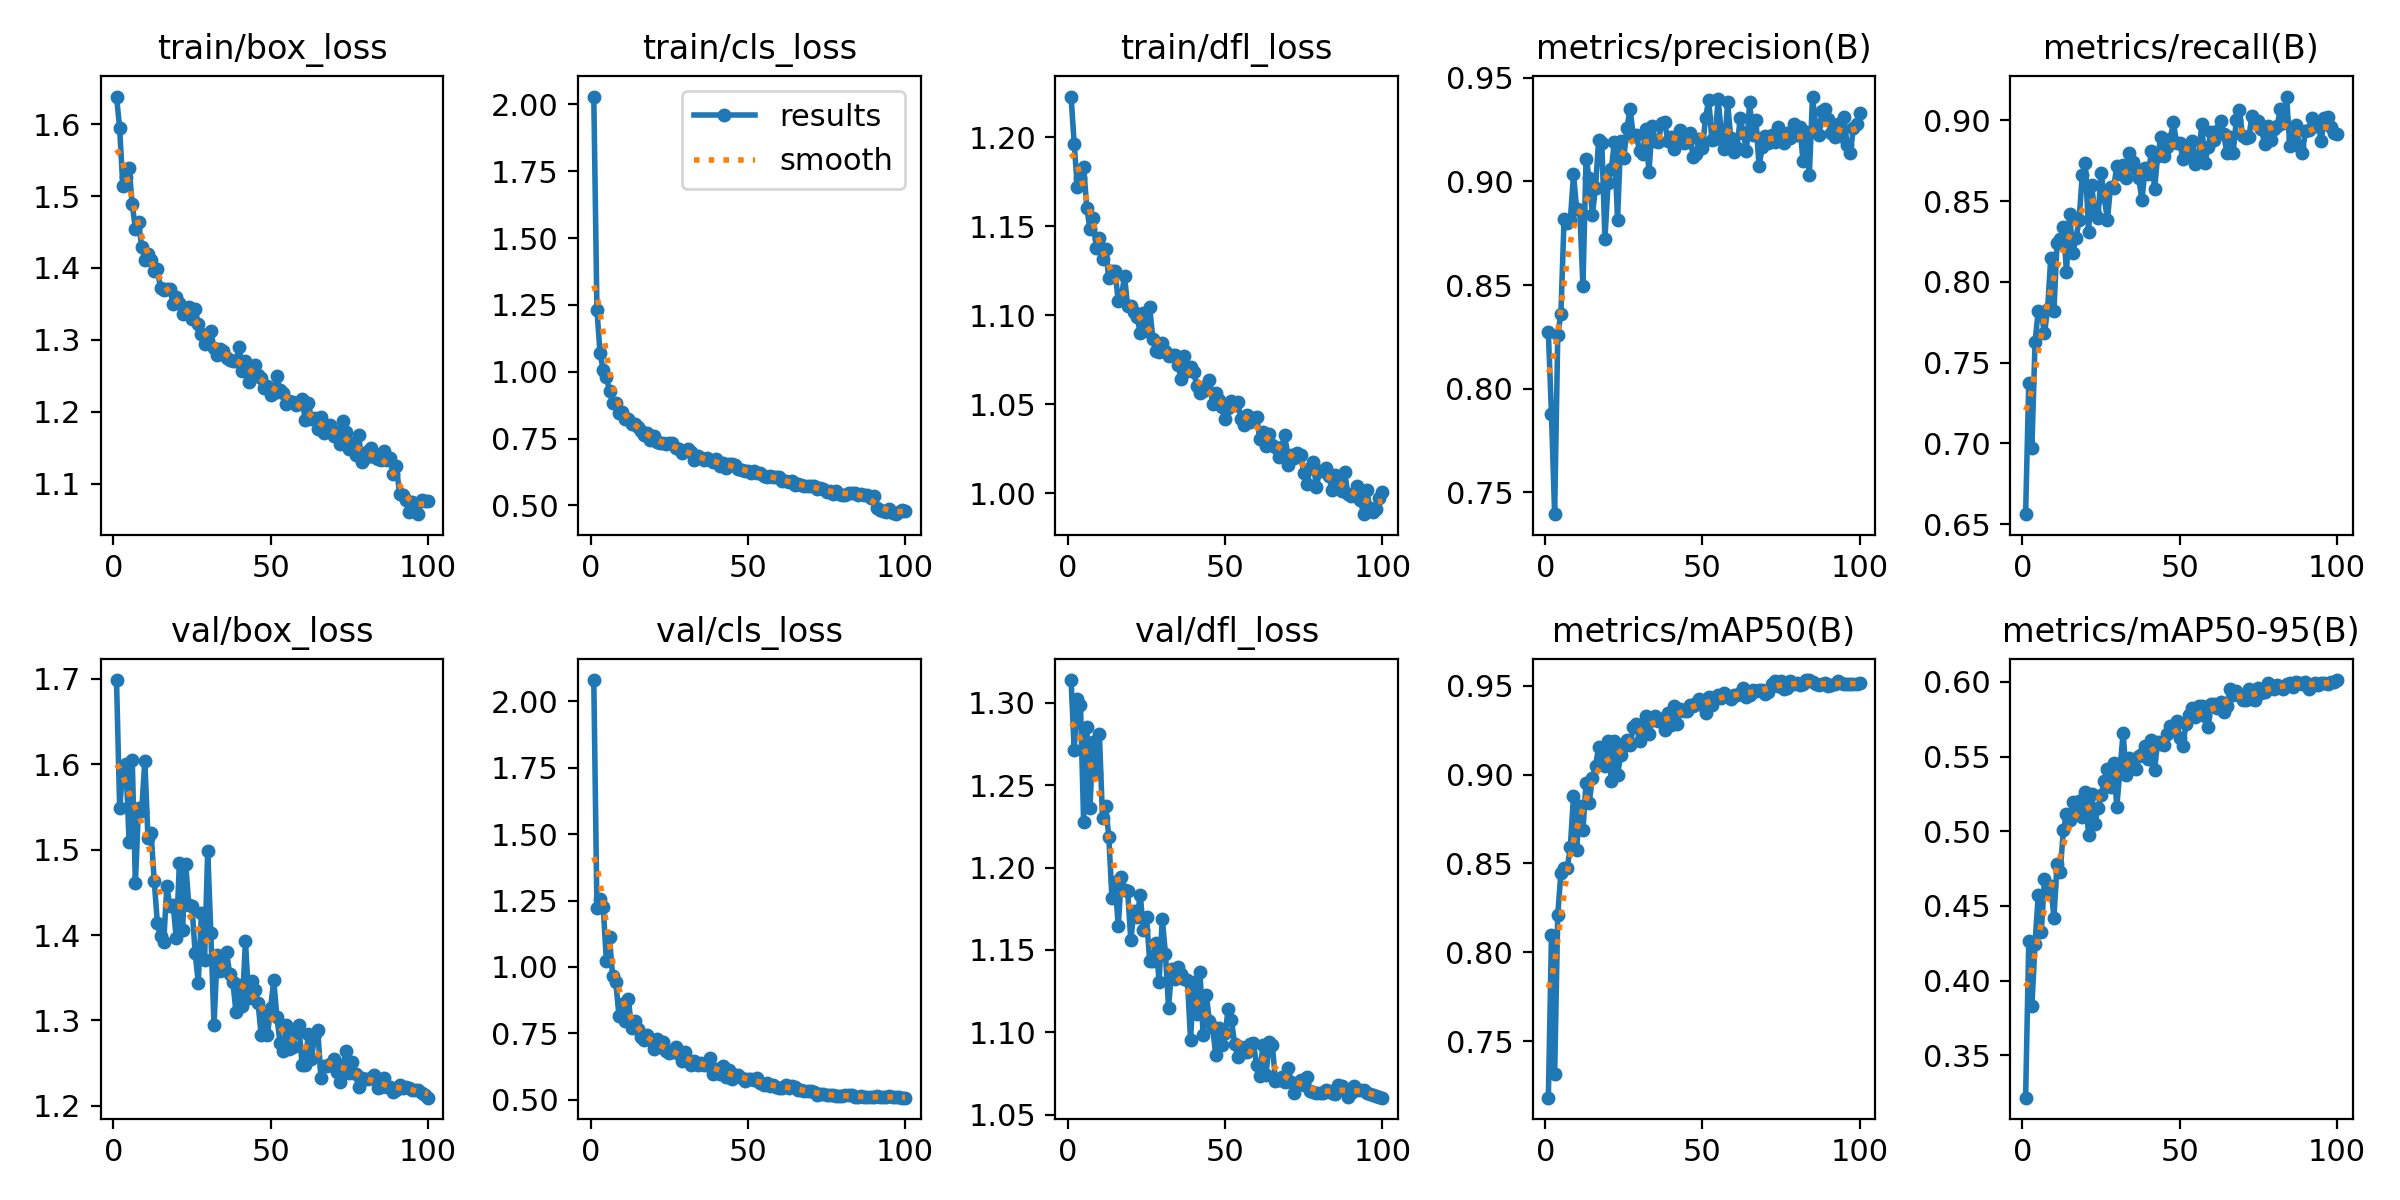

✅ confusion_matrix.png


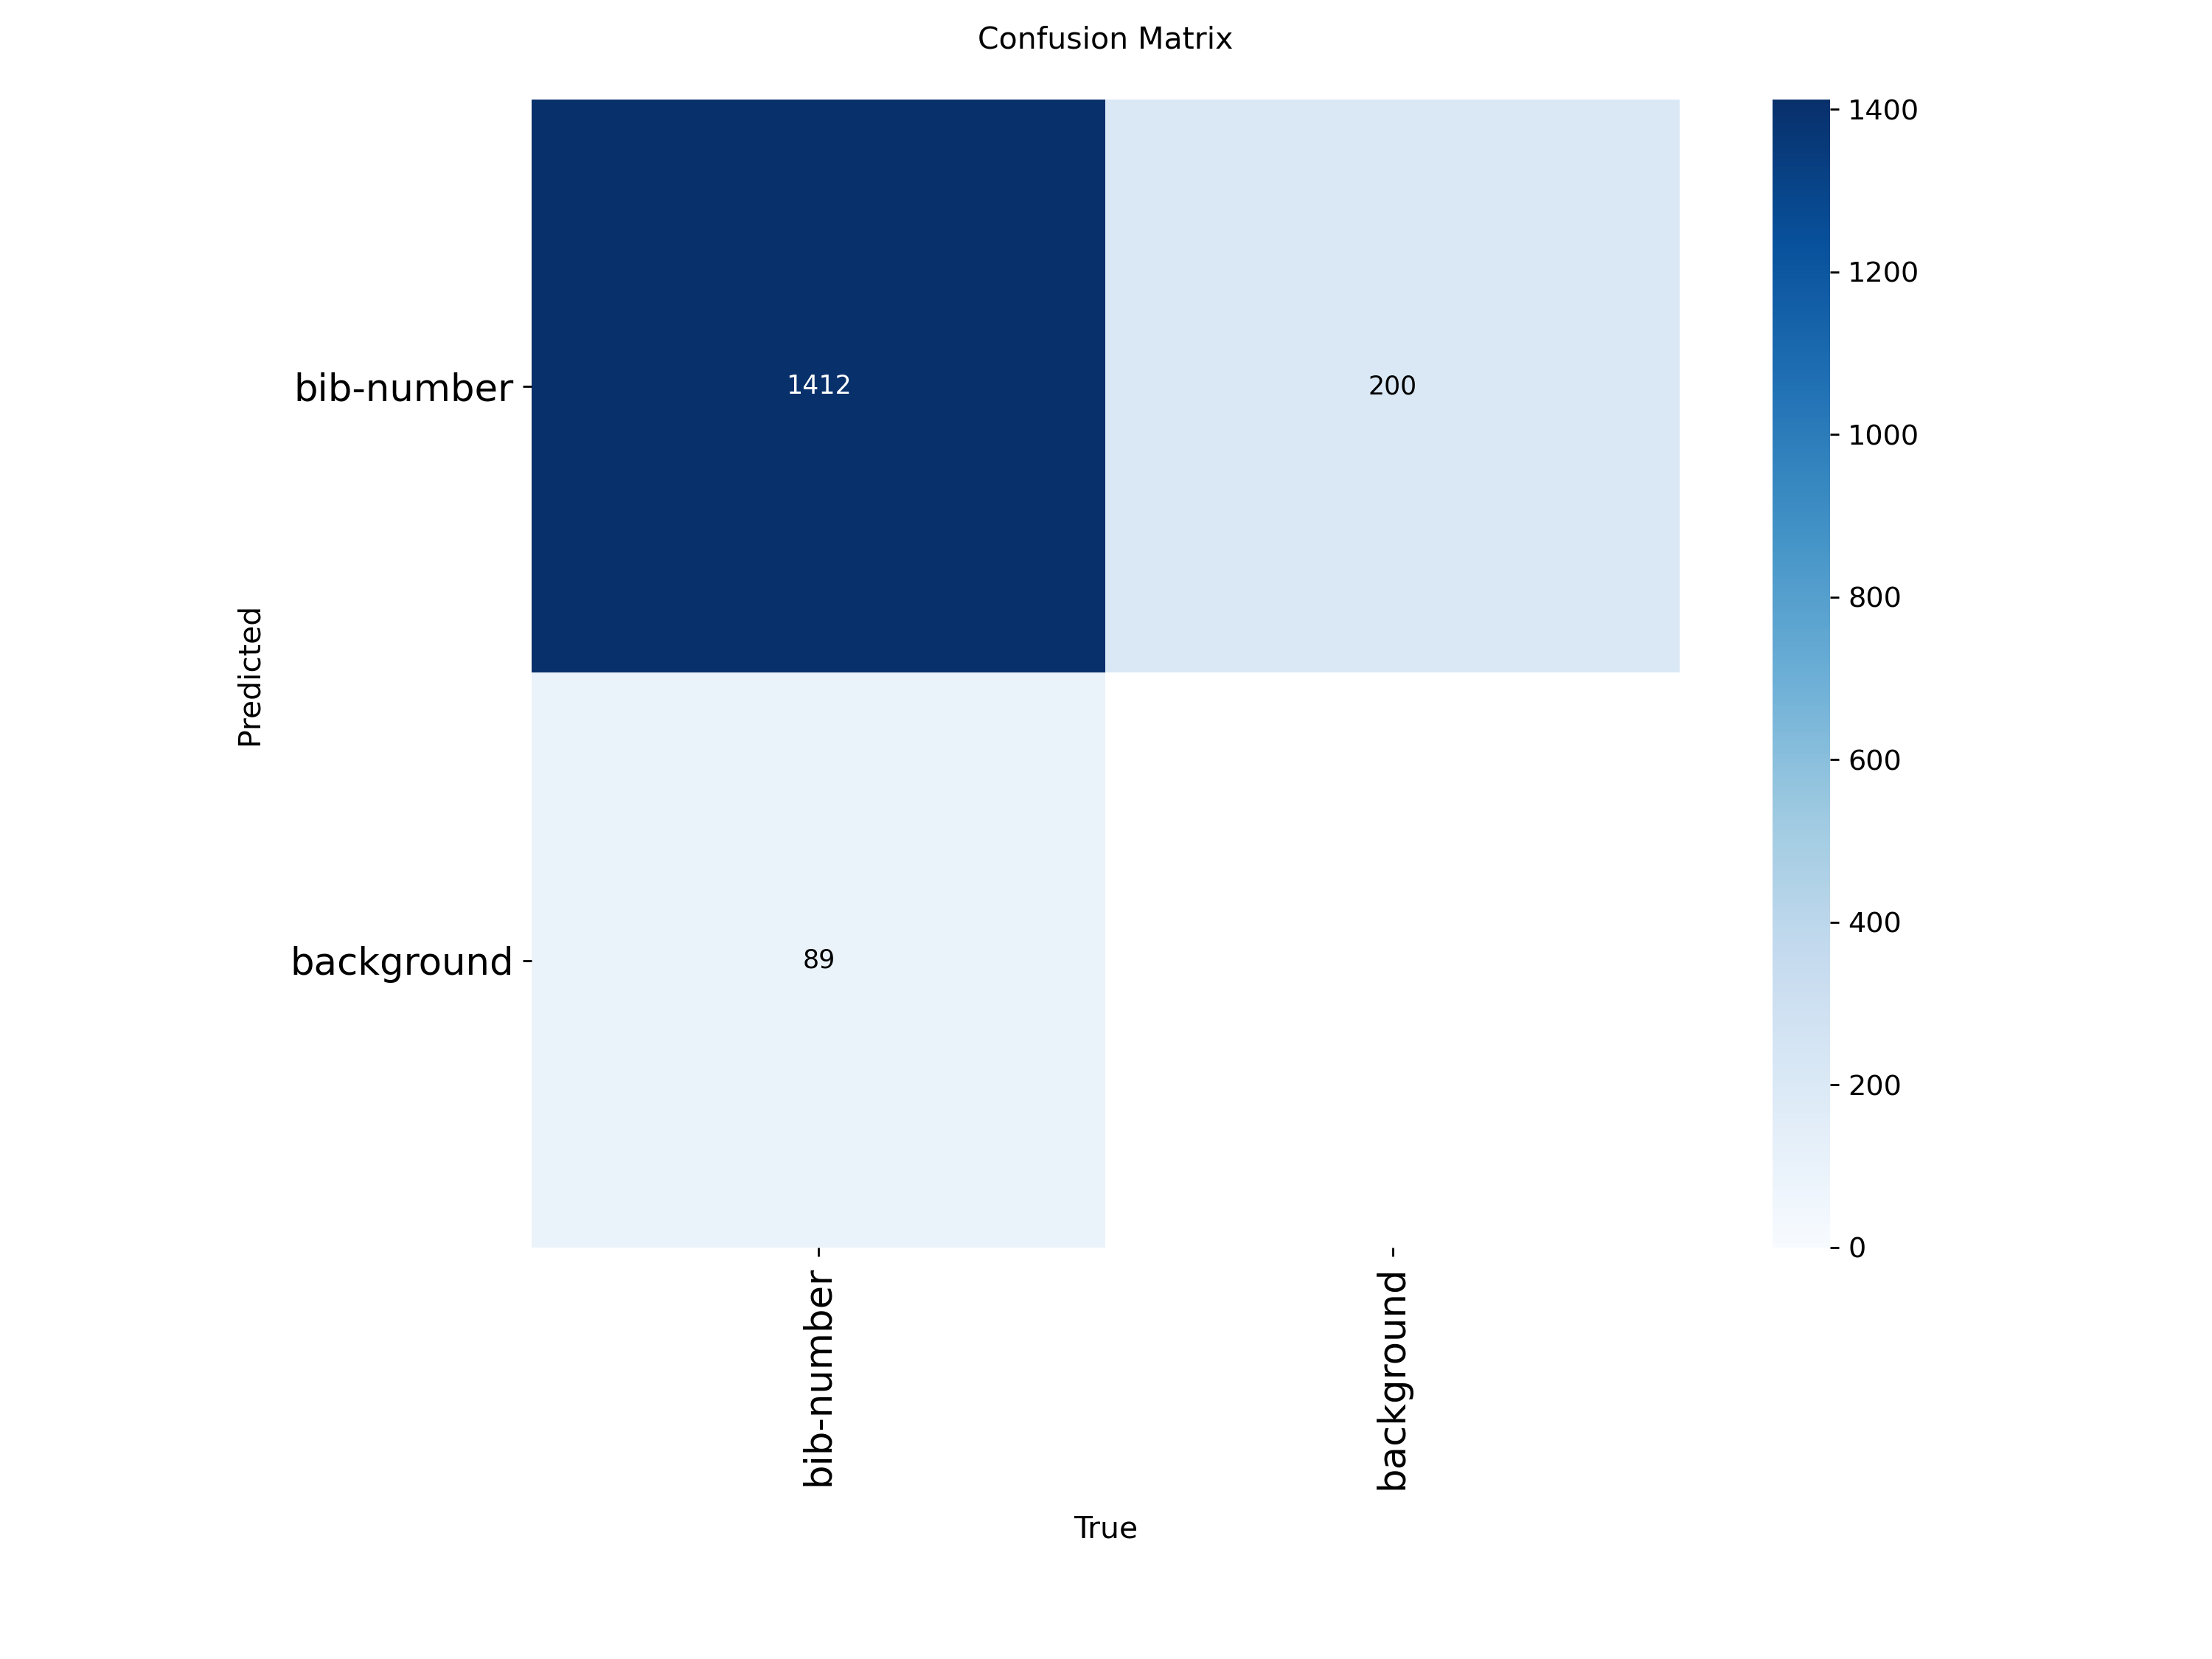

✅ confusion_matrix_normalized.png


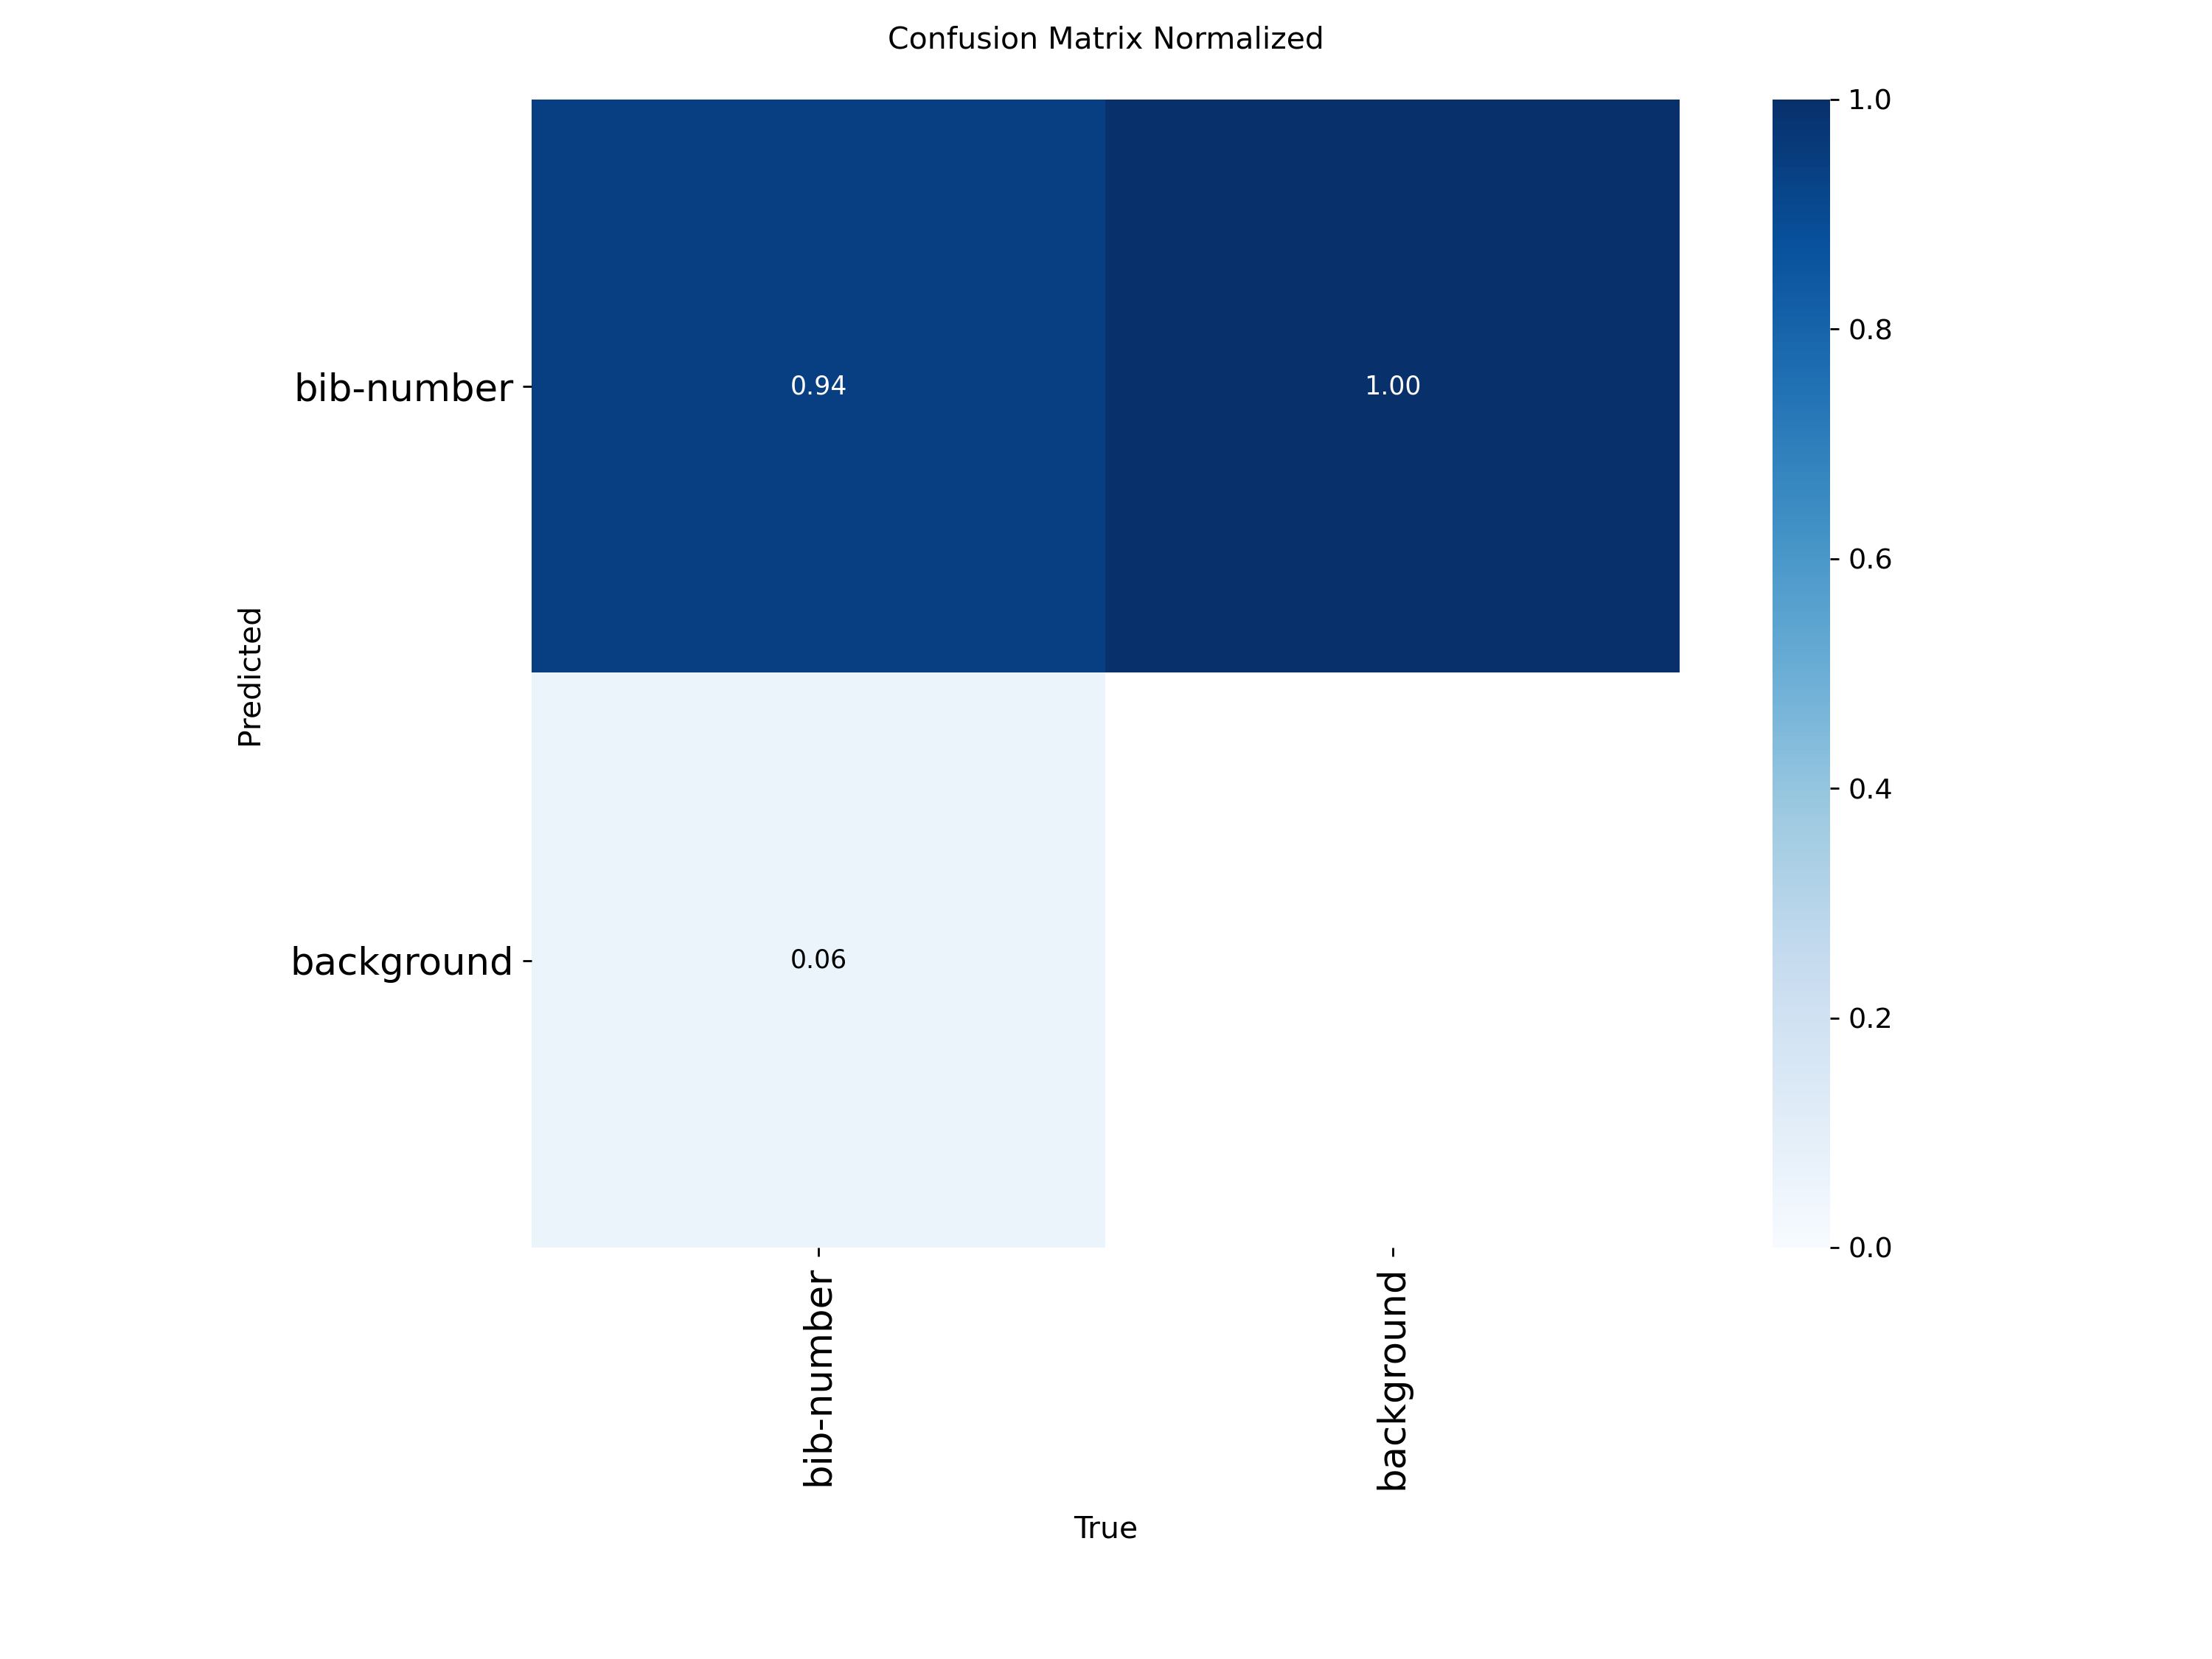

❌ PR_curve.png not found
❌ F1_curve.png not found
❌ P_curve.png not found
❌ R_curve.png not found


In [7]:
# %% [Cell 6] Training results — plots + summary metrics
import os
import glob
from IPython.display import Image, display

# Search for results.png anywhere in the current directory
results_files = glob.glob('./**/results.png', recursive=True)
print("Found results.png at:", results_files)

if results_files:
    # Use the directory of the first results.png found
    run_dir = os.path.dirname(results_files[0])
    print(f"Run directory: {run_dir}")
    
    # Display all plot files
    plot_files = ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png",
                  "PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]
    
    for img_name in plot_files:
        p = os.path.join(run_dir, img_name)
        if os.path.exists(p):
            print(f"✅ {img_name}")
            display(Image(filename=p, width=700))
        else:
            print(f"❌ {img_name} not found")
else:
    print("No results.png found. Training may not have completed or saved properly.")
    print("Current directory contents:", os.listdir('.'))

In [8]:

# %% [Cell 7] Validation set metrics (best.pt, explicit re-run)
best_weights = os.path.join(run_dir, "weights", "best.pt")
val_model = YOLO(best_weights)

val_metrics = val_model.val(data=DATA_YAML, split="val", imgsz=640, device="0,1")
print("=== VALIDATION METRICS ===")
print("mAP50:",     val_metrics.box.map50)
print("mAP50-95:",  val_metrics.box.map)
print("Precision:", val_metrics.box.mp)
print("Recall:",    val_metrics.box.mr)


Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1676.5±392.9 MB/s, size: 56.1 KB)
val: Scanning /kaggle/working/bib-number-labeling-5/valid/labels.cache... 502 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 502/502 191.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.2it/s 5.2s0.1s
                   all        502       1501      0.933      0.892      0.951      0.601
Speed: 1.1ms preprocess, 4.6ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
=== VALIDATION METRICS ===
mAP50: 0.9512212869701757
mAP50-95: 0.6012809041215152
Precision: 0.9331238694988075
Recall: 0.8923983519418499


In [9]:

# %% [Cell 8] Test set metrics
# Requires "test" split present in data.yaml (Roboflow gives you one if you chose a 3-way split)
test_metrics = val_model.val(data=DATA_YAML, split="test", imgsz=640, device="0,1")
print("=== TEST METRICS ===")
print("mAP50:",     test_metrics.box.map50)
print("mAP50-95:",  test_metrics.box.map)
print("Precision:", test_metrics.box.mp)
print("Recall:",    test_metrics.box.mr)

# Per-class AP (test set)
print("\nPer-class mAP50-95:")
for i, ap in enumerate(test_metrics.box.maps):
    cls_name = val_model.names[i]
    print(f"  {cls_name}: {ap:.4f}")


Ultralytics 8.4.102 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1393.2±555.9 MB/s, size: 54.5 KB)
val: Scanning /kaggle/working/bib-number-labeling-5/test/labels... 501 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 501/501 1.3Kit/s 0.4s<0.1s
val: New cache created: /kaggle/working/bib-number-labeling-5/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 6.3it/s 5.1s0.1s
                   all        501       1390      0.929        0.9       0.95      0.622
Speed: 1.0ms preprocess, 4.7ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
=== TEST METRICS ===
mAP50: 0.9500004224214555
mAP50-95: 0.6223990113927672
Precision: 0.9294410457030285
Recall: 0.9002820235094614

Per-class mAP50-95:
  bib-numbe

✅ Data config loaded successfully
Test directory: ../test/images

Using test images from: ../test/images
❌ Test directory not found: ../test/images
Looking for images in common locations...
✅ Found images in: /kaggle/working/bib-number-labeling-5/train/images
✅ Found model at: /kaggle/working/runs/yolo11n_bib/weights/best.pt

Making predictions on 8 images...

0: 640x640 1 bib-number, 5.0ms
1: 640x640 2 bib-numbers, 5.0ms
2: 640x640 2 bib-numbers, 5.0ms
3: 640x640 10 bib-numbers, 5.0ms
4: 640x640 24 bib-numbers, 5.0ms
5: 640x640 1 bib-number, 5.0ms
6: 640x640 2 bib-numbers, 5.0ms
7: 640x640 3 bib-numbers, 5.0ms
Speed: 1.7ms preprocess, 5.0ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/test_predictions

Predictions saved to: /kaggle/working/runs/test_predictions

Displaying 8 predictions:
  - image2.jpg


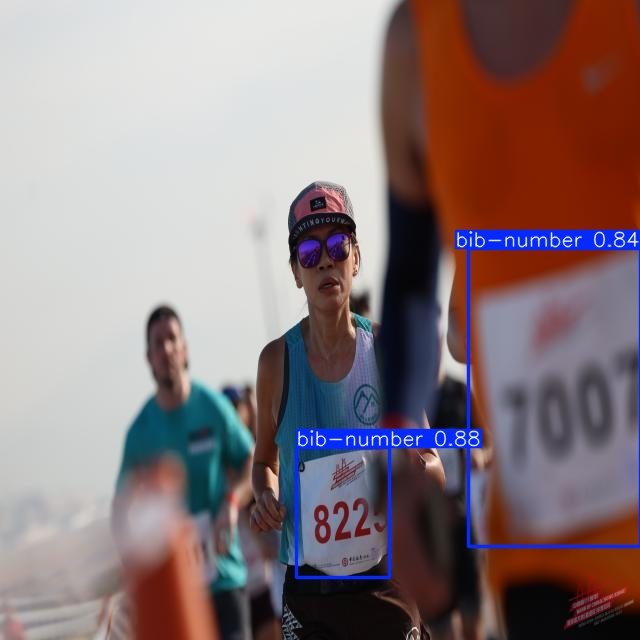

  - image5.jpg


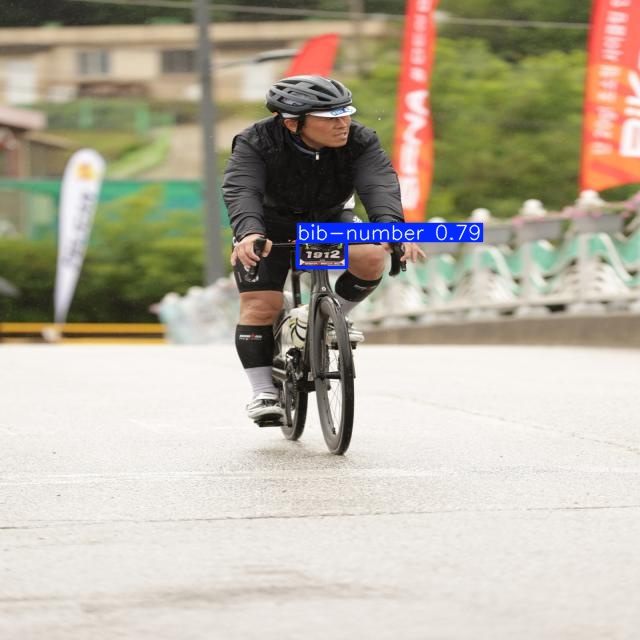

  - image1.jpg


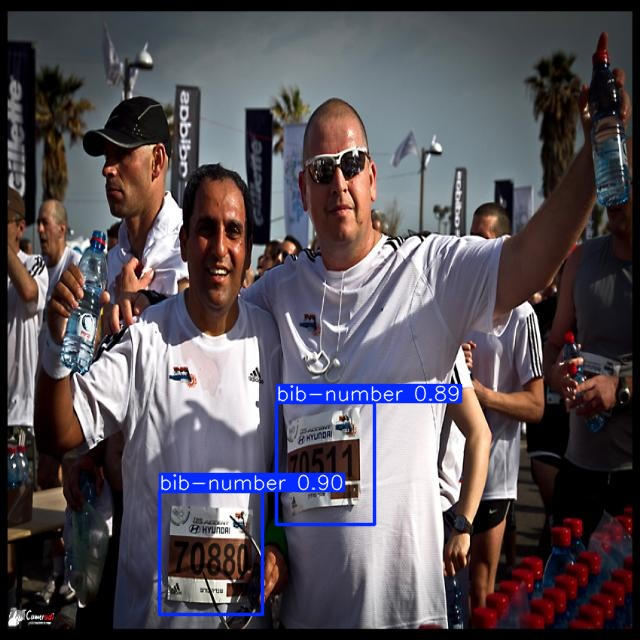

  - image6.jpg


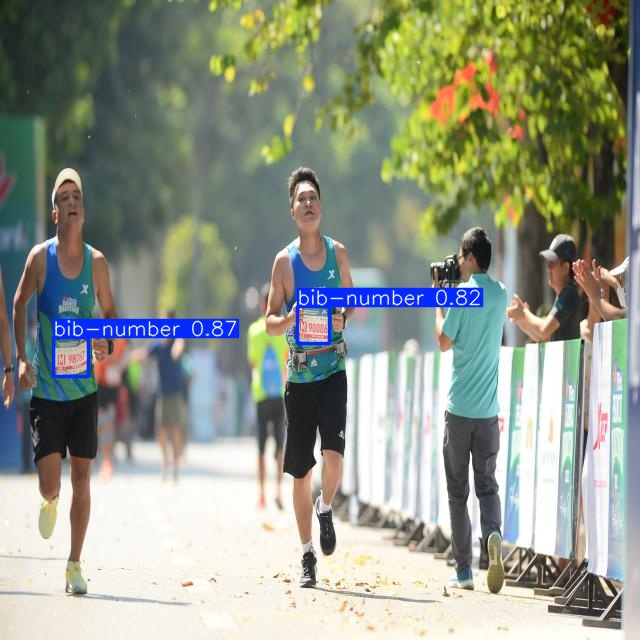

  - image0.jpg


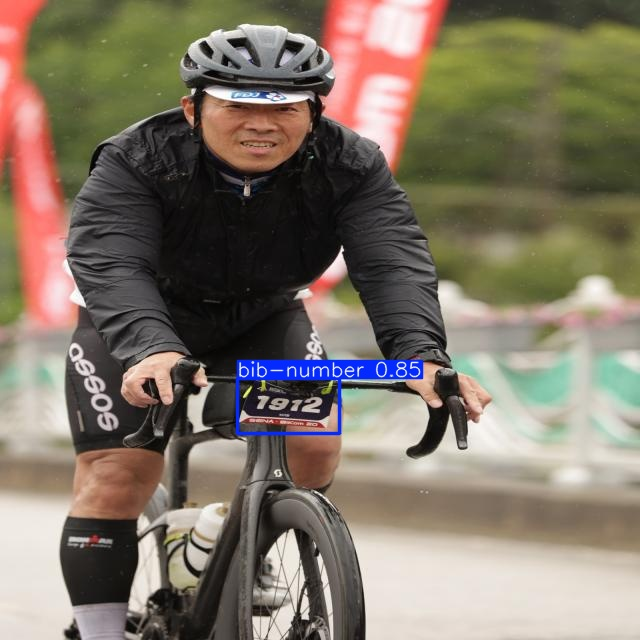

  - image3.jpg


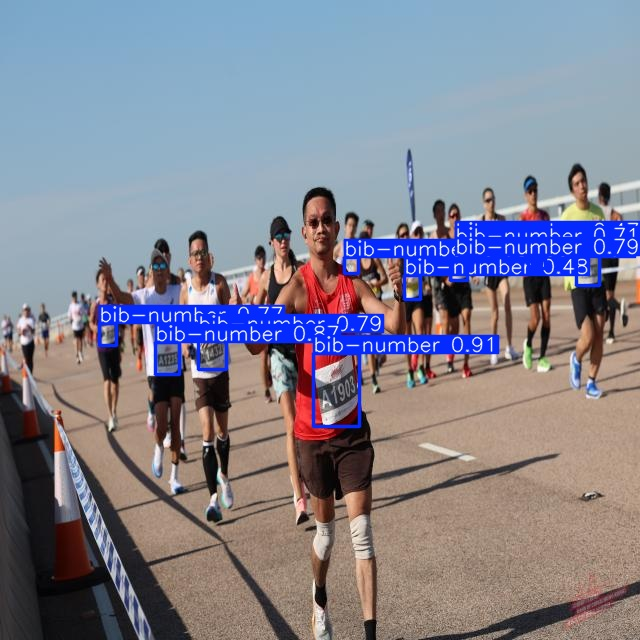

  - image7.jpg


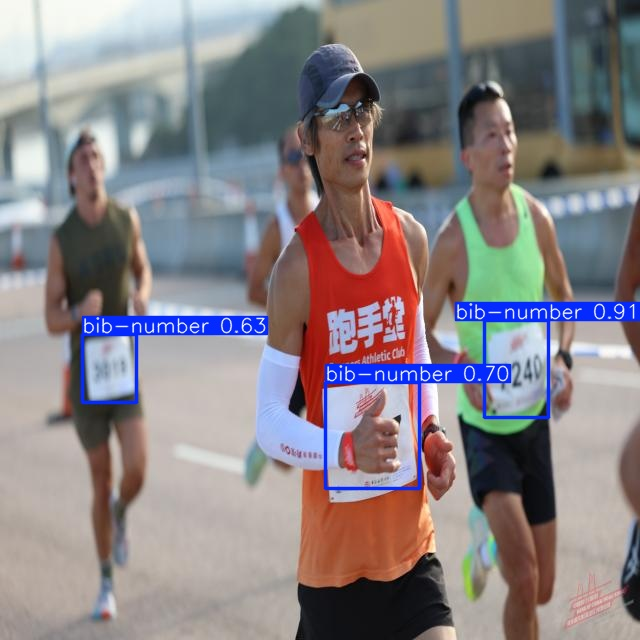

  - image4.jpg


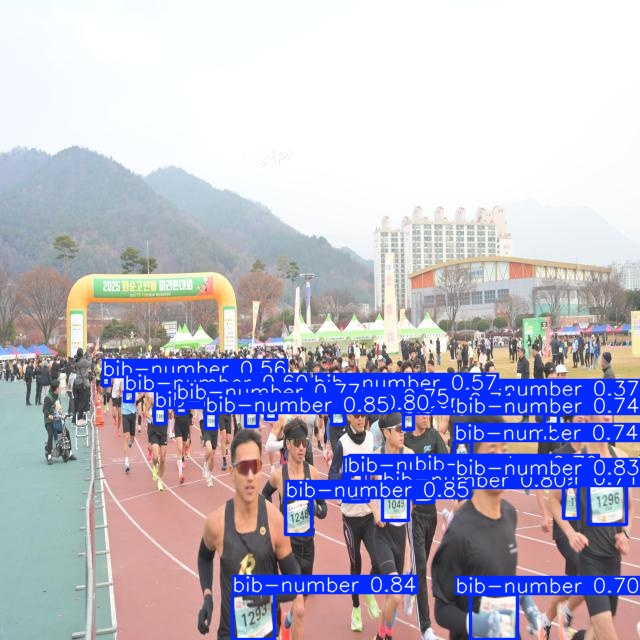

In [12]:
# %% [Cell 9] Sample predictions on test images (visual sanity check)
import os
import glob
import yaml
from IPython.display import Image, display
from ultralytics import YOLO

# Load the data configuration
data_yaml_path = '/kaggle/working/bib-number-labeling-5/data.yaml'  # Adjust path if needed

# Check if the file exists
if os.path.exists(data_yaml_path):
    with open(data_yaml_path, 'r') as f:
        data_cfg = yaml.safe_load(f)
    print("✅ Data config loaded successfully")
    print(f"Test directory: {data_cfg.get('test', 'Not specified')}")
else:
    # Try to find data.yaml
    import glob
    yaml_files = glob.glob('/kaggle/working/**/data.yaml', recursive=True)
    if yaml_files:
        data_yaml_path = yaml_files[0]
        with open(data_yaml_path, 'r') as f:
            data_cfg = yaml.safe_load(f)
        print(f"✅ Data config loaded from: {data_yaml_path}")
        print(f"Test directory: {data_cfg.get('test', 'Not specified')}")
    else:
        print("❌ data.yaml not found!")
        # Manually set test directory
        test_img_dir = '/kaggle/working/bib-number-labeling-5/test'  # Adjust as needed
        data_cfg = {'test': test_img_dir}

# Get test directory
test_img_dir = data_cfg.get('test', '/kaggle/working/bib-number-labeling-5/test')
print(f"\nUsing test images from: {test_img_dir}")

# Check if test directory exists and has images
if os.path.exists(test_img_dir):
    sample_imgs = glob.glob(os.path.join(test_img_dir, "*.jpg"))[:8]
    print(f"Found {len(sample_imgs)} sample images")
    
    if len(sample_imgs) == 0:
        # Try other image extensions
        sample_imgs = glob.glob(os.path.join(test_img_dir, "*.png"))[:8]
        sample_imgs.extend(glob.glob(os.path.join(test_img_dir, "*.jpeg"))[:8])
        sample_imgs = sample_imgs[:8]
        print(f"Found {len(sample_imgs)} images with .png/.jpeg extensions")
else:
    print(f"❌ Test directory not found: {test_img_dir}")
    print("Looking for images in common locations...")
    
    # Try to find images
    possible_dirs = [
        '/kaggle/working/bib-number-labeling-5/',
        '/kaggle/working/',
        './',
        '../working/'
    ]
    
    for dir_path in possible_dirs:
        if os.path.exists(dir_path):
            images = glob.glob(os.path.join(dir_path, "**/*.jpg"), recursive=True)[:8]
            if images:
                test_img_dir = os.path.dirname(images[0])
                sample_imgs = images[:8]
                print(f"✅ Found images in: {test_img_dir}")
                break

# Load the trained model
model_path = '/kaggle/working/runs/detect/train/weights/best.pt'  # Adjust path if needed

# Try to find the best model
if not os.path.exists(model_path):
    model_files = glob.glob('/kaggle/working/runs/yolo11n_bib/weights/best.pt', recursive=True)
    if model_files:
        model_path = model_files[0]
        print(f"✅ Found model at: {model_path}")
    else:
        print("❌ Model not found! Please train the model first.")
        # Use the validation model if available
        if 'val_model' in globals():
            model = val_model
            print("Using existing validation model")
        else:
            model = YOLO('yolo11n.pt')  # Fallback to base model
            print("Using base YOLO model as fallback")

# Make predictions
if 'sample_imgs' in locals() and len(sample_imgs) > 0:
    print(f"\nMaking predictions on {len(sample_imgs)} images...")
    
    # Load model if not already loaded
    if 'model' not in locals():
        model = YOLO(model_path)
    
    pred_results = model.predict(
        source=sample_imgs,
        imgsz=640,
        conf=0.2,
        device="0",
        save=True,
        project="/kaggle/working/runs",
        name="test_predictions",
        exist_ok=True,
    )
    
    # Display predictions
    pred_dir = pred_results[0].save_dir if hasattr(pred_results[0], 'save_dir') else "/kaggle/working/runs/test_predictions"
    print(f"\nPredictions saved to: {pred_dir}")
    
    # Find and display prediction images
    pred_images = glob.glob(os.path.join(pred_dir, "*.jpg"))[:8]
    if not pred_images:
        pred_images = glob.glob(os.path.join(pred_dir, "*.png"))[:8]
    
    if pred_images:
        print(f"\nDisplaying {len(pred_images)} predictions:")
        for img_path in pred_images:
            print(f"  - {os.path.basename(img_path)}")
            display(Image(filename=img_path, width=500))
    else:
        print("No prediction images found. Check the save directory.")
else:
    print("❌ No sample images found to make predictions on!")

In [13]:

# %% [Cell 10] Save final artifacts for download
import shutil

os.makedirs("/kaggle/working/final_model", exist_ok=True)
shutil.copy(best_weights, "/kaggle/working/final_model/yolo26n_bib_best.pt")
shutil.copy(os.path.join(run_dir, "results.csv"), "/kaggle/working/final_model/results.csv")

print("Final model + metrics saved to /kaggle/working/final_model")
print("Download from the Kaggle 'Output' tab after the notebook finishes.")

Final model + metrics saved to /kaggle/working/final_model
Download from the Kaggle 'Output' tab after the notebook finishes.


In [14]:
# %% [Cell 11] Package all results for download
import os
import shutil
import glob

# Find the actual training directory
run_dir = '/kaggle/working/runs/yolo11n_bib'  # From your output

# Verify the directory exists
if not os.path.exists(run_dir):
    # Try to find it automatically
    possible_dirs = glob.glob('/kaggle/working/runs/*/weights/best.pt')
    if possible_dirs:
        run_dir = os.path.dirname(os.path.dirname(possible_dirs[0]))  # Get parent of weights folder
        print(f"✅ Found training directory: {run_dir}")
    else:
        print("❌ Training directory not found!")
        # Check all possible locations
        possible_runs = glob.glob('/kaggle/working/runs/*/')
        print(f"Available runs: {possible_runs}")
        if possible_runs:
            run_dir = possible_runs[0]  # Use the first one found
            print(f"Using: {run_dir}")

print(f"\n📁 Using run directory: {run_dir}")

# Create download package directory
download_dir = "/kaggle/working/download_package"
os.makedirs(download_dir, exist_ok=True)

# 1. Copy weights
weights_dir = os.path.join(run_dir, "weights")
if os.path.exists(weights_dir):
    for weight_file in ["best.pt", "last.pt"]:
        src = os.path.join(weights_dir, weight_file)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(download_dir, weight_file))
            print(f"✅ Copied {weight_file}")
        else:
            print(f"❌ {weight_file} not found")
else:
    print(f"❌ Weights directory not found: {weights_dir}")

# 2. Copy metrics and log files
metric_files = ["results.csv", "results.png", "confusion_matrix.png",
                "confusion_matrix_normalized.png", "PR_curve.png",
                "F1_curve.png", "P_curve.png", "R_curve.png", "args.yaml",
                "labels.jpg", "train_batch0.jpg", "train_batch1.jpg", "train_batch2.jpg"]

print("\nCopying metric files...")
for fname in metric_files:
    src = os.path.join(run_dir, fname)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(download_dir, fname))
        print(f"  ✅ {fname}")
    else:
        print(f"  ❌ {fname} not found")

# 3. Copy data.yaml
data_yaml_path = '/kaggle/working/bib-number-labeling-5/data.yaml'
if os.path.exists(data_yaml_path):
    shutil.copy(data_yaml_path, os.path.join(download_dir, "data.yaml"))
    print(f"✅ Copied data.yaml")
else:
    # Try to find data.yaml
    yaml_files = glob.glob('/kaggle/working/**/data.yaml', recursive=True)
    if yaml_files:
        shutil.copy(yaml_files[0], os.path.join(download_dir, "data.yaml"))
        print(f"✅ Copied data.yaml from: {yaml_files[0]}")
    else:
        print("❌ data.yaml not found")

# 4. Also copy the test predictions if they exist
test_pred_dir = '/kaggle/working/runs/test_predictions'
if os.path.exists(test_pred_dir):
    pred_images = glob.glob(os.path.join(test_pred_dir, "*.jpg"))
    if pred_images:
        pred_download_dir = os.path.join(download_dir, "test_predictions")
        os.makedirs(pred_download_dir, exist_ok=True)
        for img in pred_images[:8]:  # Copy first 8 predictions
            shutil.copy(img, os.path.join(pred_download_dir, os.path.basename(img)))
        print(f"✅ Copied {len(pred_images[:8])} test predictions")

# 5. Create a summary README
readme_path = os.path.join(download_dir, "README.txt")
with open(readme_path, "w") as f:
    f.write("YOLO Model Training Results\n")
    f.write("=" * 40 + "\n\n")
    f.write(f"Model: {os.path.basename(run_dir)}\n")
    f.write(f"Training directory: {run_dir}\n\n")
    
    # Try to read metrics from results.csv
    csv_path = os.path.join(run_dir, "results.csv")
    if os.path.exists(csv_path):
        import pandas as pd
        try:
            df = pd.read_csv(csv_path)
            last_row = df.iloc[-1]
            f.write("Best Metrics (from last epoch):\n")
            for col in df.columns:
                if col not in ['epoch', 'time']:
                    f.write(f"  {col}: {last_row[col]:.4f}\n")
        except:
            f.write("Metrics could not be parsed from CSV\n")
    
    f.write("\nFiles included:\n")
    for file in os.listdir(download_dir):
        f.write(f"  - {file}\n")

print(f"\n✅ README.txt created")

# Show all packaged files
print("\n" + "="*50)
print("📦 Packaged files in download_package:")
for f in sorted(os.listdir(download_dir)):
    file_path = os.path.join(download_dir, f)
    if os.path.isdir(file_path):
        print(f"  📁 {f}/")
        for subf in os.listdir(file_path):
            print(f"      - {subf}")
    else:
        size = os.path.getsize(file_path) / 1024  # KB
        print(f"  📄 {f} ({size:.1f} KB)")

print("\n" + "="*50)
print(f"✅ All files packaged to: {download_dir}")

# For Kaggle, you can download this folder directly
print("\n💡 To download: Go to the 'Output' tab and download 'download_package'")


📁 Using run directory: /kaggle/working/runs/yolo11n_bib
✅ Copied best.pt
✅ Copied last.pt

Copying metric files...
  ✅ results.csv
  ✅ results.png
  ✅ confusion_matrix.png
  ✅ confusion_matrix_normalized.png
  ❌ PR_curve.png not found
  ❌ F1_curve.png not found
  ❌ P_curve.png not found
  ❌ R_curve.png not found
  ✅ args.yaml
  ✅ labels.jpg
  ✅ train_batch0.jpg
  ✅ train_batch1.jpg
  ✅ train_batch2.jpg
✅ Copied data.yaml
✅ Copied 8 test predictions

✅ README.txt created

📦 Packaged files in download_package:
  📄 README.txt (0.7 KB)
  📄 args.yaml (1.6 KB)
  📄 best.pt (5350.0 KB)
  📄 confusion_matrix.png (104.4 KB)
  📄 confusion_matrix_normalized.png (99.8 KB)
  📄 data.yaml (0.3 KB)
  📄 labels.jpg (103.4 KB)
  📄 last.pt (5350.0 KB)
  📄 results.csv (12.3 KB)
  📄 results.png (294.3 KB)
  📁 test_predictions/
      - image2.jpg
      - image5.jpg
      - image1.jpg
      - image6.jpg
      - image0.jpg
      - image3.jpg
      - image7.jpg
      - image4.jpg
  📄 train_batch0.jpg (625.6 KB)


In [15]:
# %% [Cell 12] Zip it into a single downloadable file
zip_path = "/kaggle/working/download_package"
shutil.make_archive(zip_path, "zip", download_dir)
print("Created:", zip_path + ".zip")
print("Size (MB):", round(os.path.getsize(zip_path + ".zip") / (1024*1024), 2))

Created: /kaggle/working/download_package.zip
Size (MB): 12.26
